# Group 5 — Jiji Uganda Product Listing Analysis

**Course:** DSC2107  
**Source:** Group 5's Jiji Uganda web-scraping project  
**Purpose:** Explore product prices, price outliers, category/brand composition, discounts, and changes in listing ranks over time.

> **Important data limitation:** The supplied archive contains five scrape dates (14–18 October 2026), not seven complete days. The data also does not contain product ratings, review counts, or seller names, and old-price/discount fields are mostly blank. The notebook therefore does not invent those values. It analyses the available evidence and explicitly identifies questions that cannot be answered from this scrape.

## 1. Setup and load the raw snapshots

Keep this notebook in the same folder as the supplied ZIP, or extract the ZIP first. The loader first looks for extracted JSON files and otherwise reads the JSON snapshots directly from the ZIP archive.

In [1]:
from pathlib import Path
import json, zipfile, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 11

ZIP_PATH = Path("DSC2107-Course-Project-Group-5-Web-scraping-.zip")
RAW_GLOB = "**/scraper/data/raw/jiji_ug_*.json"

raw_files = list(Path(".").glob(RAW_GLOB))
raw_records = []

if raw_files:
    for path in raw_files:
        with open(path, "r", encoding="utf-8") as f:
            raw_records.append(json.load(f))
elif ZIP_PATH.exists():
    with zipfile.ZipFile(ZIP_PATH) as zf:
        names = [n for n in zf.namelist()
                 if "/scraper/data/raw/jiji_ug_" in n and n.endswith(".json")]
        for name in sorted(names):
            with zf.open(name) as f:
                raw_records.append(json.load(f))
else:
    raise FileNotFoundError(
        "Place the supplied project ZIP beside this notebook, or extract it first."
    )

frames = []
for raw in raw_records:
    run_date = raw.get("meta", {}).get("run_id")
    snap = pd.DataFrame(raw.get("snapshot", []))
    if not snap.empty:
        snap["date"] = run_date
        frames.append(snap)

df = pd.concat(frames, ignore_index=True)
df["date"] = pd.to_datetime(df["date"], errors="coerce")
print(f"Snapshots: {len(raw_records)} | Listing observations: {len(df):,}")
print("Dates:", ", ".join(d.strftime("%Y-%m-%d") for d in sorted(df["date"].dropna().unique())))
print("Categories:", ", ".join(sorted(df["category"].dropna().unique())))
display(df.head())

Snapshots: 6 | Listing observations: 3,482
Dates: 2026-10-14, 2026-10-15, 2026-10-16, 2026-10-17, 2026-10-18, 2026-10-19
Categories: mobile-phones, smart-watches, tablets


,listing_id,url,category_slug,area_slug,title,title_source,price_raw,price_old_raw,discount_pct_raw,condition_raw,location_raw,index_position,category,page,rank_in_category,scraped_at,run_id,date
0,q9Lwf7V0MgKrnDd562lBszEm,https://jiji.ug/central-division/mobile-phones...,mobile-phones,central-division,5,text,"UGX 400,000",None,None,Brand New,"Kampala, Central Division",0,mobile-phones,1,1,2026-10-13T21:34:37+00:00,2026-10-14,2026-10-14
1,5VS6WNMEOSQ2vQSgIt1VISGI,https://jiji.ug/central-division/mobile-phones...,mobile-phones,central-division,5,text,"UGX 330,000",None,None,Brand New,"Kampala, Central Division",1,mobile-phones,1,2,2026-10-13T21:34:37+00:00,2026-10-14,2026-10-14
2,kNcnpIuc79HiFCDk8JYan3g5,https://jiji.ug/central-division/mobile-phones...,mobile-phones,central-division,5,text,"UGX 360,000",None,None,Brand New,"Kampala, Central Division",2,mobile-phones,1,3,2026-10-13T21:34:37+00:00,2026-10-14,2026-10-14
3,fAh363Iz2zGxtVlTGAJNkFct,https://jiji.ug/central-division/mobile-phones...,mobile-phones,central-division,Apple iPhone 11 Pro 256 GB White,text,"UGX 900,000",None,None,Refurbished,"Kampala, Central Division",3,mobile-phones,1,4,2026-10-13T21:34:37+00:00,2026-10-14,2026-10-14
4,7ZdQu8i50FksiXIc3uZVlaB9,https://jiji.ug/central-division/mobile-phones...,mobile-phones,central-division,New Samsung Galaxy A73 5G 256 GB Black,text,"UGX 420,000",None,None,Brand New,"Kampala, Central Division",4,mobile-phones,1,5,2026-10-13T21:34:37+00:00,2026-10-14,2026-10-14


## 2. Clean key fields

Prices are parsed from the displayed UGX text. A displayed listing price is an asking price, not a confirmed transaction price. We retain missing prices and flag implausibly low values rather than silently deleting them. The brand extraction is deliberately heuristic and should be treated as an approximation.

In [2]:
def parse_money(value):
    if pd.isna(value) or not str(value).strip():
        return np.nan
    digits = re.sub(r"[^0-9.]", "", str(value))
    try:
        return float(digits) if digits else np.nan
    except ValueError:
        return np.nan

df["price_ugx"] = df["price_raw"].map(parse_money)
df["old_price_ugx"] = df["price_old_raw"].map(parse_money)
df["discount_badge_pct"] = df["discount_pct_raw"].map(parse_money)
df["rank"] = pd.to_numeric(df["rank_in_category"], errors="coerce")
df["date_only"] = df["date"].dt.date
df["category"] = df["category"].astype("string").str.replace("-", " ", regex=False).str.title()
df["title"] = df["title"].fillna("").astype(str)

BRAND_ALIASES = {
    "Apple": ["apple", "iphone", "ipad", "airpods"],
    "Samsung": ["samsung"], "Tecno": ["tecno"], "Infinix": ["infinix"],
    "Itel": ["itel"], "Xiaomi": ["xiaomi", "redmi", "poco"],
    "Oppo": ["oppo"], "Vivo": ["vivo"], "Realme": ["realme"],
    "Nokia": ["nokia"], "Huawei": ["huawei"], "Honor": ["honor"],
    "Google": ["google", "pixel"], "Motorola": ["motorola", "moto"],
    "OnePlus": ["oneplus"], "Lenovo": ["lenovo"], "Oraimo": ["oraimo"],
    "Garmin": ["garmin"], "Fitbit": ["fitbit"], "HP": ["hp"], "Dell": ["dell"]
}
def infer_brand(title):
    low = title.lower()
    matches = []
    for brand, aliases in BRAND_ALIASES.items():
        for alias in aliases:
            m = re.search(r"\b" + re.escape(alias) + r"\b", low)
            if m:
                matches.append((m.start(), brand))
    return sorted(matches)[0][1] if matches else "Unidentified"

df["brand_inferred"] = df["title"].map(infer_brand)
df["has_old_price"] = df["old_price_ugx"].notna()
df["has_discount_badge"] = df["discount_badge_pct"].notna()
df["valid_price"] = df["price_ugx"].notna() & (df["price_ugx"] >= 10000)

overview = pd.DataFrame({
    "Metric": ["Listing observations", "Unique listing IDs", "Dates observed",
               "Categories", "Missing displayed prices", "Prices below UGX 10,000",
               "Rows with old price", "Rows with discount badge"],
    "Value": [len(df), df["listing_id"].nunique(), df["date"].nunique(),
              df["category"].nunique(), int(df["price_ugx"].isna().sum()),
              int((df["price_ugx"].notna() & (df["price_ugx"] < 10000)).sum()),
              int(df["has_old_price"].sum()), int(df["has_discount_badge"].sum())]
})
display(overview)
display(df.groupby(["date_only", "category"]).size().unstack(fill_value=0))

,Metric,Value
0,Listing observations,3482
1,Unique listing IDs,2325
2,Dates observed,6
3,Categories,3
4,Missing displayed prices,0
5,"Prices below UGX 10,000",0
6,Rows with old price,7
7,Rows with discount badge,7


category,Mobile Phones,Smart Watches,Tablets
date_only,,,
2026-10-14,200,200,200
2026-10-15,200,200,200
2026-10-16,200,200,200
2026-10-17,200,200,200
2026-10-18,178,200,157
2026-10-19,147,200,200


## 3. Question (a): What does the price distribution look like in each category? Identify outliers.

Use boxplots to compare category distributions and the IQR rule to flag potential outliers. Outliers are not automatically errors: premium devices may legitimately cost much more than typical listings.

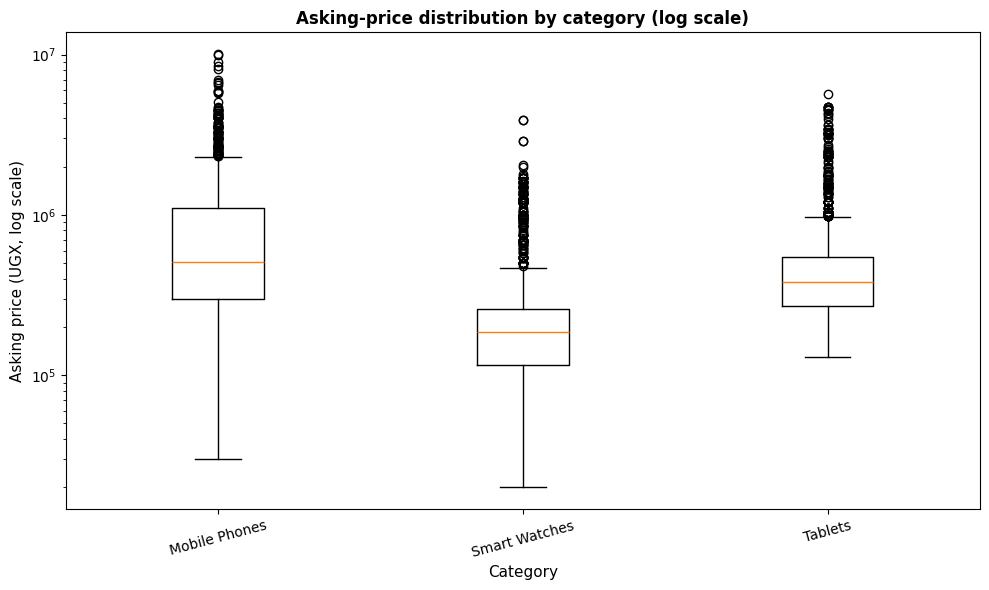

,count,median,mean,minimum,maximum
category,,,,,
Mobile Phones,1125,510000.0,952127.0,30000.0,10100000.0
Smart Watches,1200,185000.0,300321.0,20000.0,3900000.0
Tablets,1157,380000.0,607968.0,130000.0,5700000.0


Potential IQR outliers: 440


,date,category,title,price_ugx,iqr_lower_bound,iqr_upper_bound,url
52,2026-10-16,Mobile Phones,New Apple iPhone 18 Pro Max 1 TB Bronze,10100000.0,-900000.0,2300000.0,https://jiji.ug/central-division/mobile-phones...
6,2026-10-14,Mobile Phones,New Samsung Galaxy Z Trifold 512 GB Black,10000000.0,-900000.0,2300000.0,https://jiji.ug/central-division/mobile-phones...
24,2026-10-14,Mobile Phones,New Apple iPhone 18 Pro Max 512 GB,9000000.0,-900000.0,2300000.0,https://jiji.ug/central-division/mobile-phones...
41,2026-10-15,Mobile Phones,New Apple iPhone 18 Pro Max 512 GB Red,8500000.0,-900000.0,2300000.0,https://jiji.ug/central-division/mobile-phones...
74,2026-10-17,Mobile Phones,New Apple iPhone 18 Pro Max 512 GB,8200000.0,-900000.0,2300000.0,https://jiji.ug/central-division/mobile-phones...
59,2026-10-16,Mobile Phones,New Samsung Galaxy Fold 512 GB Purple,6950000.0,-900000.0,2300000.0,https://jiji.ug/central-division/mobile-phones...
55,2026-10-16,Mobile Phones,New Apple iPhone 18 Pro 512 GB Purple,6750000.0,-900000.0,2300000.0,https://jiji.ug/central-division/mobile-phones...
56,2026-10-16,Mobile Phones,New Apple iPhone 18 Pro 512 GB Blue,6650000.0,-900000.0,2300000.0,https://jiji.ug/central-division/mobile-phones...
32,2026-10-15,Mobile Phones,Apple iPhone 18 Pro Max 256 GB Purple,6500000.0,-900000.0,2300000.0,https://jiji.ug/central-division/mobile-phones...
53,2026-10-16,Mobile Phones,New Apple iPhone 18 Pro 256 GB Black,5900000.0,-900000.0,2300000.0,https://jiji.ug/central-division/mobile-phones...


In [3]:
price_df = df.loc[df["valid_price"]].copy()
if price_df.empty:
    print("No usable prices were parsed; inspect price_raw before continuing.")
else:
    order = sorted(price_df["category"].dropna().unique())
    fig, ax = plt.subplots()
    ax.boxplot([price_df.loc[price_df["category"] == c, "price_ugx"].dropna()
                for c in order], tick_labels=order, showfliers=True)
    ax.set_yscale("log")
    ax.set_title("Asking-price distribution by category (log scale)")
    ax.set_ylabel("Asking price (UGX, log scale)")
    ax.set_xlabel("Category")
    ax.tick_params(axis="x", rotation=15)
    plt.tight_layout()
    plt.show()

    price_summary = price_df.groupby("category")["price_ugx"].agg(
        count="count", median="median", mean="mean", minimum="min", maximum="max"
    ).round(0)
    display(price_summary)

    def iqr_bounds(s):
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        return q1 - 1.5 * iqr, q3 + 1.5 * iqr

    outlier_parts = []
    for category, group in price_df.groupby("category"):
        low, high = iqr_bounds(group["price_ugx"])
        part = group[(group["price_ugx"] < low) | (group["price_ugx"] > high)].copy()
        part["iqr_lower_bound"] = low
        part["iqr_upper_bound"] = high
        outlier_parts.append(part)
    outliers = pd.concat(outlier_parts, ignore_index=True) if outlier_parts else pd.DataFrame()
    print(f"Potential IQR outliers: {len(outliers)}")
    display(outliers[["date", "category", "title", "price_ugx", "iqr_lower_bound",
                      "iqr_upper_bound", "url"]].sort_values("price_ugx", ascending=False).head(20))

## 4. Question (b): Is price related to rating, or review count related to rank/popularity?

The supplied raw records contain **no rating or review-count fields**, so those relationships cannot be tested from this dataset. We can instead examine the available relationship between asking price and rank/position as a limited visibility proxy. Lower rank numbers mean a listing appeared nearer the top, but promotions and page sorting can affect this measure.

Spearman correlation between price and rank: 0.016


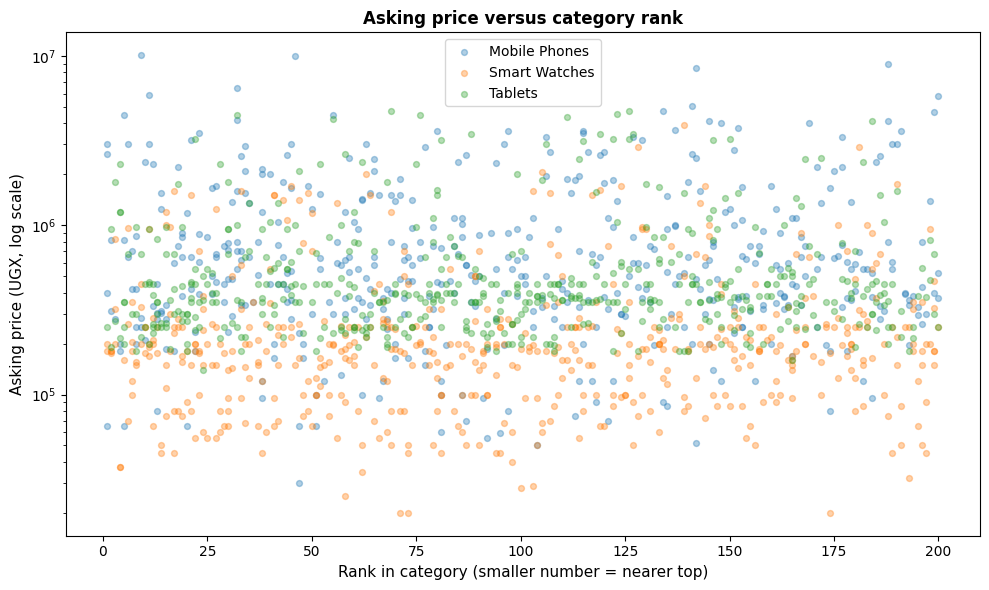

Rating and review-count correlations are not estimable: those fields were not scraped.


In [4]:
rank_price = df.loc[df["valid_price"] & df["rank"].notna(), ["price_ugx", "rank", "category"]].copy()
if len(rank_price) >= 3:
    corr = rank_price[["price_ugx", "rank"]].corr(method="spearman").iloc[0, 1]
    print(f"Spearman correlation between price and rank: {corr:.3f}")
    fig, ax = plt.subplots()
    sample = rank_price.sample(min(1500, len(rank_price)), random_state=42)
    for category, g in sample.groupby("category"):
        ax.scatter(g["rank"], g["price_ugx"], alpha=0.35, s=18, label=category)
    ax.set_yscale("log")
    ax.set_title("Asking price versus category rank")
    ax.set_xlabel("Rank in category (smaller number = nearer top)")
    ax.set_ylabel("Asking price (UGX, log scale)")
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Not enough valid price/rank pairs for correlation.")
print("Rating and review-count correlations are not estimable: those fields were not scraped.")

## 5. Question (c): How did prices, discounts and rankings change over the observed period? Which products moved most?

The archive has seven scrape dates (13–19 October). Repeated listing IDs allow approximate tracking of listing price and rank. Rank movement is measured as first observed rank minus last observed rank; positive values indicate movement toward the top of the category. Because promoted placements and scraped pages can change, rank movement is a visibility proxy, not a direct measure of sales or popularity.

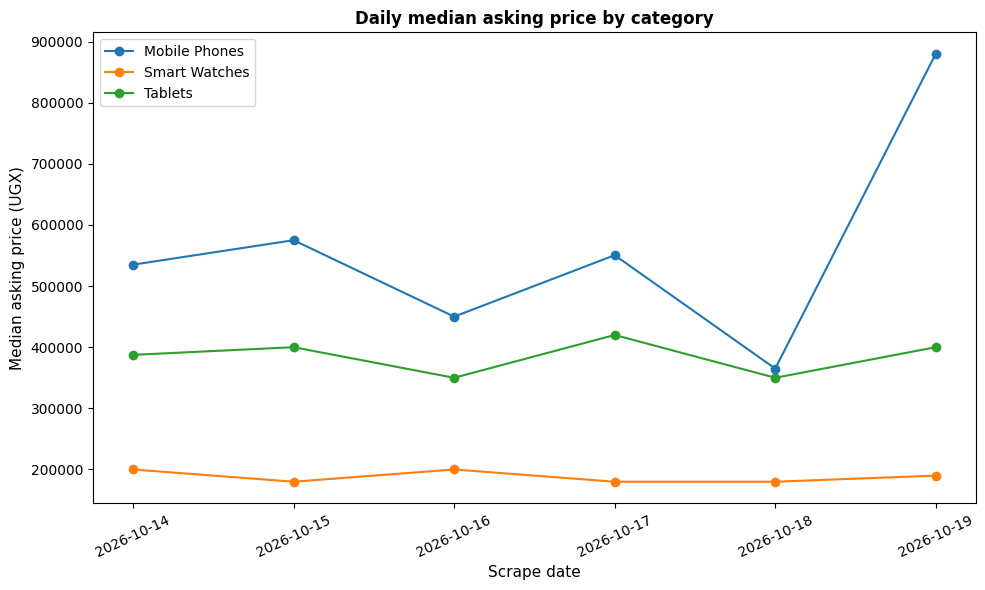

Listings observed on 2+ dates: 658
Largest movements toward the top of category ranking:


,title,category,first_date,last_date,first_rank,last_rank,rank_improvement,url
648,New Samsung Galaxy A30 64 GB Black,Mobile Phones,2026-10-17,2026-10-19,196,4,192,https://jiji.ug/central-division/mobile-phones...
333,Timeless GT4 Haino Teko Smart Watch,Smart Watches,2026-10-15,2026-10-19,199,20,179,https://jiji.ug/central-division/smart-watches...
339,New Samsung Galaxy S25 Ultra 256 GB,Mobile Phones,2026-10-14,2026-10-15,183,8,175,https://jiji.ug/central-division/mobile-phones...
155,New Discover Note 20 Plus 512 GB Blue,Tablets,2026-10-14,2026-10-19,192,17,175,https://jiji.ug/central-division/tablets/new-d...
22,New Samsung Galaxy Tab S10 Lite 128 GB Black,Tablets,2026-10-14,2026-10-18,181,12,169,https://jiji.ug/central-division/tablets/new-s...
273,Samsung Galaxy S10 128 GB Green,Mobile Phones,2026-10-16,2026-10-17,196,28,168,https://jiji.ug/makindye/mobile-phones/samsung...
459,New Modio M129 512 GB Black,Tablets,2026-10-14,2026-10-18,184,16,168,https://jiji.ug/central-division/tablets/new-m...
237,New Tablet 1 TB Blue,Tablets,2026-10-17,2026-10-19,169,2,167,https://jiji.ug/central-division/tablets/new-t...
94,New Mobile Phone 8 GB Black,Mobile Phones,2026-10-15,2026-10-19,178,16,162,https://jiji.ug/central-division/mobile-phones...
624,New Bebe B2060 256 GB Black,Tablets,2026-10-14,2026-10-19,175,14,161,https://jiji.ug/central-division/tablets/new-b...


Largest absolute asking-price changes among tracked listings:


,title,category,first_price_ugx,last_price_ugx,price_change_ugx,url
471,Google Pixel 8a 128 GB Blue,Mobile Phones,850000.0,900000.0,50000.0,https://jiji.ug/central-division/mobile-phones...
609,Google Pixel 8a 128 GB Black,Mobile Phones,850000.0,900000.0,50000.0,https://jiji.ug/central-division/mobile-phones...
384,New Modio M92 1 TB Gray,Tablets,380000.0,420000.0,40000.0,https://jiji.ug/central-division/tablets/new-m...
300,New Modio M797 256 GB Black,Tablets,230000.0,250000.0,20000.0,https://jiji.ug/central-division/tablets/new-m...
3,Atouch HL7 Smart Watch,Smart Watches,80000.0,80000.0,0.0,https://jiji.ug/central-division/smart-watches...
4,Notch GT4 Haino Teko Smart Watch,Smart Watches,180000.0,180000.0,0.0,https://jiji.ug/central-division/smart-watches...
5,Oraimo Watch 6n,Smart Watches,80000.0,80000.0,0.0,https://jiji.ug/central-division/smart-watches...
6,New Discover Note 13 Plus 256 GB Silver,Tablets,450000.0,450000.0,0.0,https://jiji.ug/central-division/tablets/new-d...
7,New Modio M71 256 GB Blue,Tablets,180000.0,180000.0,0.0,https://jiji.ug/central-division/tablets/new-m...
8,"Hainoteko G8max Golden Smart Watch, 45 Days Ac...",Smart Watches,175000.0,175000.0,0.0,https://jiji.ug/central-division/smart-watches...


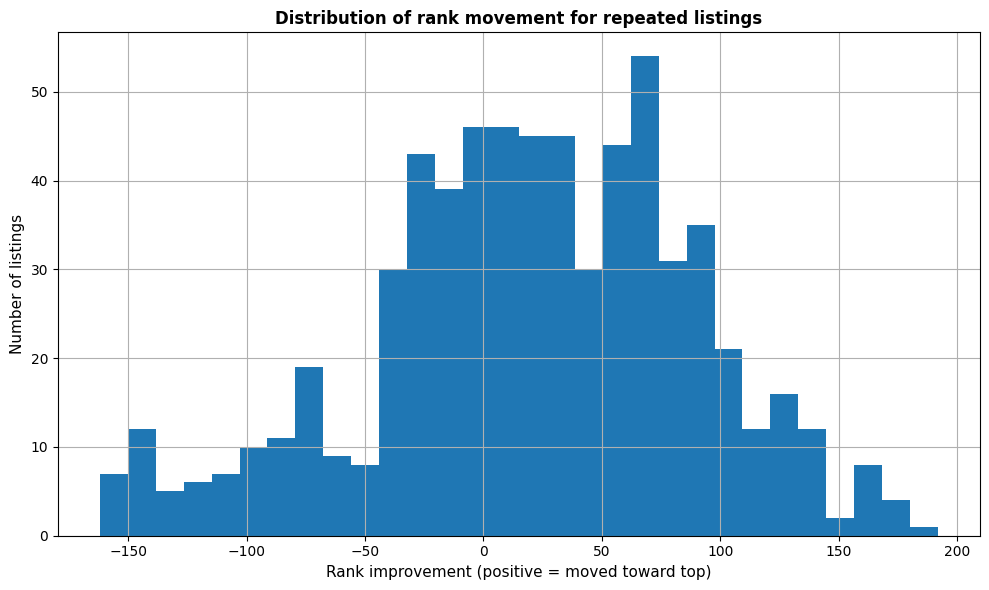

,observations,old_price_rows,discount_badge_rows
date_only,,,
2026-10-14,600,2,2
2026-10-15,600,1,1
2026-10-16,600,1,1
2026-10-17,600,1,1
2026-10-18,535,1,1
2026-10-19,547,1,1


In [5]:
daily = (price_df.groupby(["date_only", "category"])["price_ugx"]
         .median().reset_index(name="median_price_ugx"))
fig, ax = plt.subplots()
for category, g in daily.groupby("category"):
    ax.plot(pd.to_datetime(g["date_only"]), g["median_price_ugx"], marker="o", label=category)
ax.set_title("Daily median asking price by category")
ax.set_xlabel("Scrape date")
ax.set_ylabel("Median asking price (UGX)")
ax.legend()
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# Track only listings seen on at least two different scrape dates.
tracked = df.dropna(subset=["listing_id", "date", "rank"]).sort_values("date")
tracked = tracked.groupby("listing_id").filter(lambda g: g["date"].nunique() >= 2)
movement_rows = []
for listing_id, g in tracked.groupby("listing_id"):
    g = g.sort_values("date")
    first, last = g.iloc[0], g.iloc[-1]
    movement_rows.append({
        "listing_id": listing_id, "title": last["title"], "category": last["category"],
        "first_date": first["date"].date(), "last_date": last["date"].date(),
        "first_rank": first["rank"], "last_rank": last["rank"],
        "rank_improvement": first["rank"] - last["rank"],
        "first_price_ugx": first["price_ugx"], "last_price_ugx": last["price_ugx"],
        "price_change_ugx": (last["price_ugx"] - first["price_ugx"])
            if pd.notna(last["price_ugx"]) and pd.notna(first["price_ugx"]) else np.nan,
        "url": last["url"]
    })
movement = pd.DataFrame(movement_rows)
print(f"Listings observed on 2+ dates: {len(movement):,}")
if not movement.empty:
    print("Largest movements toward the top of category ranking:")
    display(movement.sort_values("rank_improvement", ascending=False)[
        ["title", "category", "first_date", "last_date", "first_rank", "last_rank",
         "rank_improvement", "url"]].head(10))
    print("Largest absolute asking-price changes among tracked listings:")
    movement["abs_price_change"] = movement["price_change_ugx"].abs()
    display(movement.dropna(subset=["price_change_ugx"]).sort_values(
        "abs_price_change", ascending=False)[
        ["title", "category", "first_price_ugx", "last_price_ugx",
         "price_change_ugx", "url"]].head(10))

    fig, ax = plt.subplots()
    movement["rank_improvement"].dropna().hist(bins=30, ax=ax)
    ax.set_title("Distribution of rank movement for repeated listings")
    ax.set_xlabel("Rank improvement (positive = moved toward top)")
    ax.set_ylabel("Number of listings")
    plt.tight_layout()
    plt.show()

# Daily discount evidence availability
discount_daily = df.groupby("date_only").agg(
    observations=("listing_id", "size"),
    old_price_rows=("old_price_ugx", "count"),
    discount_badge_rows=("discount_badge_pct", "count")
)
display(discount_daily)

## 6. Question (d): Which brands or sellers dominate each category?

Seller names are absent from the supplied records. Brands are inferred from listing titles using a keyword dictionary, so brand counts are approximate and some products remain unidentified. This chart counts listing observations; the same listing may be counted on multiple dates. Use unique listing IDs for a deduplicated listing-level view.

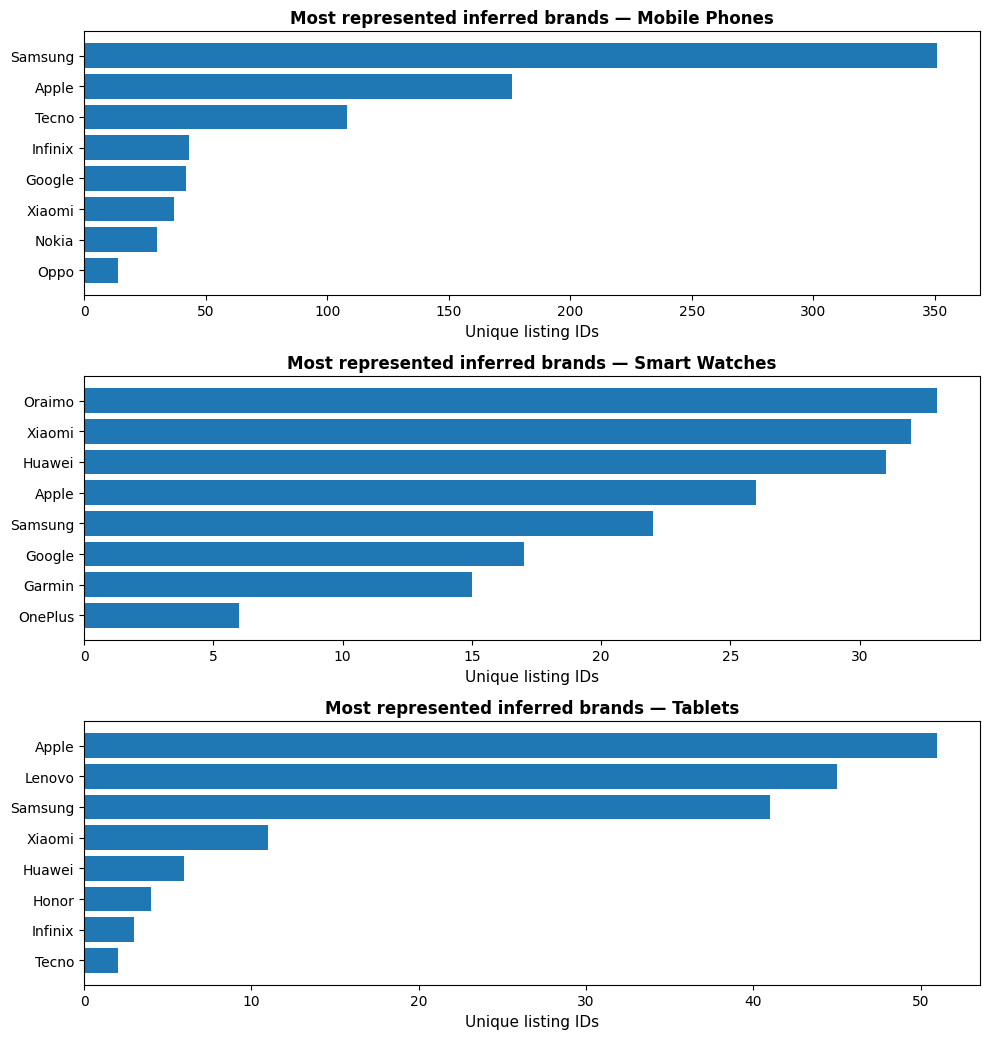

Seller dominance cannot be assessed because seller identity/name was not included in the scraped fields.


In [6]:
brand_counts = (df.groupby(["category", "brand_inferred"])["listing_id"]
                .nunique().reset_index(name="unique_listings"))
brand_counts = brand_counts[brand_counts["brand_inferred"] != "Unidentified"]
top_brands = (brand_counts.sort_values(["category", "unique_listings"], ascending=[True, False])
              .groupby("category").head(8))
if not top_brands.empty:
    categories = top_brands["category"].unique()
    fig, axes = plt.subplots(len(categories), 1, figsize=(10, max(4, 3.5 * len(categories))))
    if len(categories) == 1:
        axes = [axes]
    for ax, category in zip(axes, categories):
        g = top_brands[top_brands["category"] == category].sort_values("unique_listings")
        ax.barh(g["brand_inferred"], g["unique_listings"])
        ax.set_title(f"Most represented inferred brands — {category}")
        ax.set_xlabel("Unique listing IDs")
    plt.tight_layout()
    plt.show()
else:
    print("No brands could be inferred from the titles.")
print("Seller dominance cannot be assessed because seller identity/name was not included in the scraped fields.")

## 7. Question (e): What share of products are discounted, and how large are the discounts really?

The discount badge and old-price fields are sparsely populated. A product is counted as verifiably discounted only when an old price greater than the current price is available. The effective discount is calculated as `(old price − current price) / old price × 100`. Missing old prices are not treated as zero discounts; the results are a lower bound on the discounts visible in this scrape.

Unique listing IDs in snapshots: 2,325
Unique IDs with verifiable old-price discount: 2
Verifiable discounted share of unique IDs: 0.09%
Rows with an old price recorded: 7
Rows with a discount badge recorded: 7


,discounted_rows,median_discount_pct,mean_discount_pct,maximum_discount_pct
category,,,,
Mobile Phones,1,15.97,15.97,15.97
Tablets,6,10.00,10.00,10.00


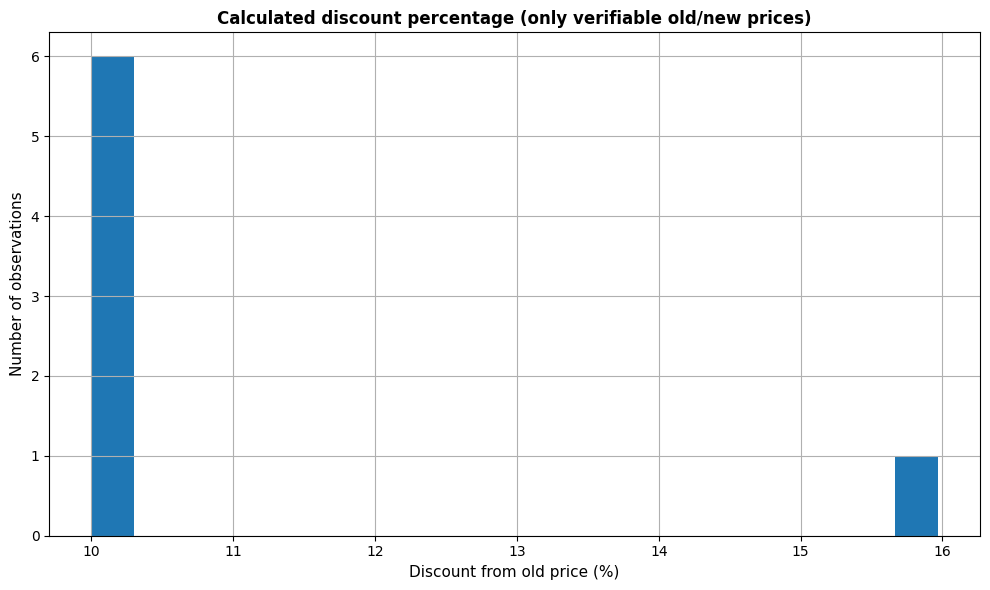

In [7]:
discount_df = df.loc[df["price_ugx"].notna() & df["old_price_ugx"].notna()].copy()
discount_df = discount_df[discount_df["old_price_ugx"] > discount_df["price_ugx"]]
discount_df["calculated_discount_pct"] = (
    (discount_df["old_price_ugx"] - discount_df["price_ugx"])
    / discount_df["old_price_ugx"] * 100
)
n_unique = df["listing_id"].nunique()
n_discounted = discount_df["listing_id"].nunique()
print(f"Unique listing IDs in snapshots: {n_unique:,}")
print(f"Unique IDs with verifiable old-price discount: {n_discounted:,}")
print(f"Verifiable discounted share of unique IDs: {100*n_discounted/n_unique:.2f}%"
      if n_unique else "No listing IDs available.")
print(f"Rows with an old price recorded: {df['old_price_ugx'].notna().sum():,}")
print(f"Rows with a discount badge recorded: {df['discount_badge_pct'].notna().sum():,}")
if not discount_df.empty:
    display(discount_df.groupby("category")["calculated_discount_pct"].agg(
        discounted_rows="count", median_discount_pct="median", mean_discount_pct="mean",
        maximum_discount_pct="max").round(2))
    fig, ax = plt.subplots()
    discount_df["calculated_discount_pct"].hist(bins=20, ax=ax)
    ax.set_title("Calculated discount percentage (only verifiable old/new prices)")
    ax.set_xlabel("Discount from old price (%)")
    ax.set_ylabel("Number of observations")
    plt.tight_layout()
    plt.show()
else:
    print("No valid old-price/current-price pairs were found; discount magnitude cannot be estimated.")

## 8. Additional group question

**Which category has the greatest price variability relative to its typical price?**

We compare the coefficient of variation (standard deviation divided by mean) for valid prices. This normalises variability so categories with different price levels can be compared. Extreme prices can inflate the statistic, so interpret it alongside the boxplot and median/IQR.

,count,mean,std,median,coefficient_of_variation
category,,,,,
Smart Watches,1200,300321.167,382295.797,185000.0,1.273
Mobile Phones,1125,952127.378,1180729.934,510000.0,1.240
Tablets,1157,607968.104,704001.076,380000.0,1.158


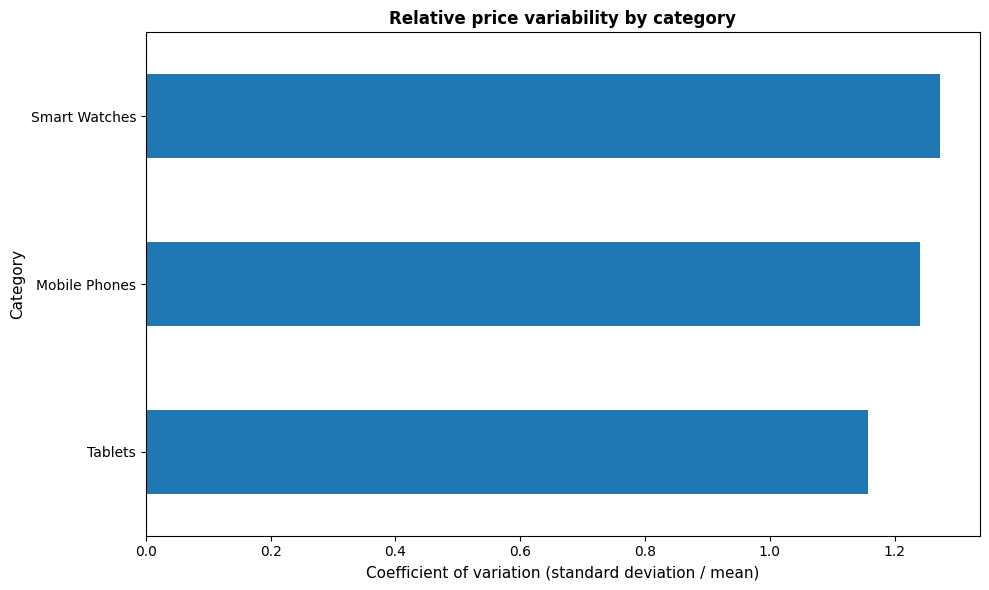

In [8]:
variability = price_df.groupby("category")["price_ugx"].agg(["count", "mean", "std", "median"])
variability["coefficient_of_variation"] = variability["std"] / variability["mean"]
variability = variability.sort_values("coefficient_of_variation", ascending=False)
display(variability.round(3))
if not variability.empty:
    fig, ax = plt.subplots()
    variability["coefficient_of_variation"].sort_values().plot(kind="barh", ax=ax)
    ax.set_title("Relative price variability by category")
    ax.set_xlabel("Coefficient of variation (standard deviation / mean)")
    ax.set_ylabel("Category")
    plt.tight_layout()
    plt.show()

## 9. Conclusions and reporting checklist

Use the actual tables and chart outputs above to write evidence-based conclusions. Do not claim results for unavailable variables.

- **Price distribution/outliers:** report category medians, ranges, and the highest-price IQR outliers; inspect outliers manually before calling them errors.
- **Price/rating and reviews/rank:** ratings and review counts are not present. Discuss only the exploratory price-versus-rank proxy.
- **Seven-day trends:** only five scrape dates are present in this archive. Describe the observed 14–18 October period and request two additional days if the assignment strictly requires seven.
- **Brand/seller dominance:** brands are heuristically inferred; seller names are unavailable.
- **Discounts:** old-price and discount badge coverage is limited. Report the verifiable discounted share as a lower bound, not the true platform-wide discount rate.
- **Data quality:** page positions are affected by promoted ads, and the sample captures only a subset of all Jiji listings. Relative posting dates and title-based brand parsing are approximate.

### At least six labelled charts included
1. Asking-price boxplot by category
2. Asking price versus rank
3. Daily median asking price by category
4. Rank-movement histogram
5. Top inferred brands by category
6. Calculated discount distribution (when verifiable pairs exist)
7. Relative price variability by category

**Suggested final presentation:** select the clearest six or more charts, number each figure, state the observation period and sample size, and include one or two sentences interpreting each figure.